# Task 4: Sentiment Analysis with NLP
**EliteTech Intern – Data Analytics Internship**

**Objective:** Perform sentiment analysis on textual data (tweets) using NLP techniques, and show **data preprocessing, model implementation and insights**.

**Dataset:** [Twitter US Airline Sentiment](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment). It contains **14,640 tweets** (14,485 after removing duplicate tweet IDs) about six US airlines (February 2015). Each tweet is labelled **negative, neutral or positive** by human annotators, and negative tweets also have a reason (late flight, customer service, and so on).

**Contents**
1. Load and explore the data
2. Text preprocessing (cleaning, tokenisation, stop-word removal, lemmatisation)
3. Model 1: VADER, a rule-based (lexicon) sentiment baseline
4. Model 2: TF-IDF + machine-learning classifiers (Naive Bayes, Logistic Regression, Linear SVM)
5. Evaluation and error analysis
6. Business insights for the airlines

In [1]:
# Import libraries
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
LABELS = ["negative", "neutral", "positive"]
PALETTE = {"negative": "#D1495B", "neutral": "#9AA5B1", "positive": "#2A9D8F"}

# Download the NLTK resources we need (only downloads them the first time)
for resource, path in [("stopwords", "corpora/stopwords"), ("wordnet", "corpora/wordnet"),
                       ("omw-1.4", "corpora/omw-1.4"), ("vader_lexicon", "sentiment/vader_lexicon.zip")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(resource, quiet=True)

## 1. Load and explore the data

In [2]:
df = pd.read_csv("../data/airline_tweets.csv")
df = df[["tweet_id", "airline", "airline_sentiment", "airline_sentiment_confidence",
         "negativereason", "retweet_count", "text", "tweet_created"]]
df = df.drop_duplicates(subset="tweet_id")
print("Tweets:", len(df))
df.head()

Tweets: 14485


,tweet_id,airline,airline_sentiment,airline_sentiment_confidence,negativereason,retweet_count,text,tweet_created
0,570306133677760513,Virgin America,neutral,1.0000,NaN,0,@VirginAmerica What @dhepburn said.,2015-02-24 11:35:52 -0800
1,570301130888122368,Virgin America,positive,0.3486,NaN,0,@VirginAmerica plus you've added commercials t...,2015-02-24 11:15:59 -0800
2,570301083672813571,Virgin America,neutral,0.6837,NaN,0,@VirginAmerica I didn't today... Must mean I n...,2015-02-24 11:15:48 -0800
3,570301031407624196,Virgin America,negative,1.0000,Bad Flight,0,@VirginAmerica it's really aggressive to blast...,2015-02-24 11:15:36 -0800
4,570300817074462722,Virgin America,negative,1.0000,Can't Tell,0,@VirginAmerica and it's a really big bad thing...,2015-02-24 11:14:45 -0800


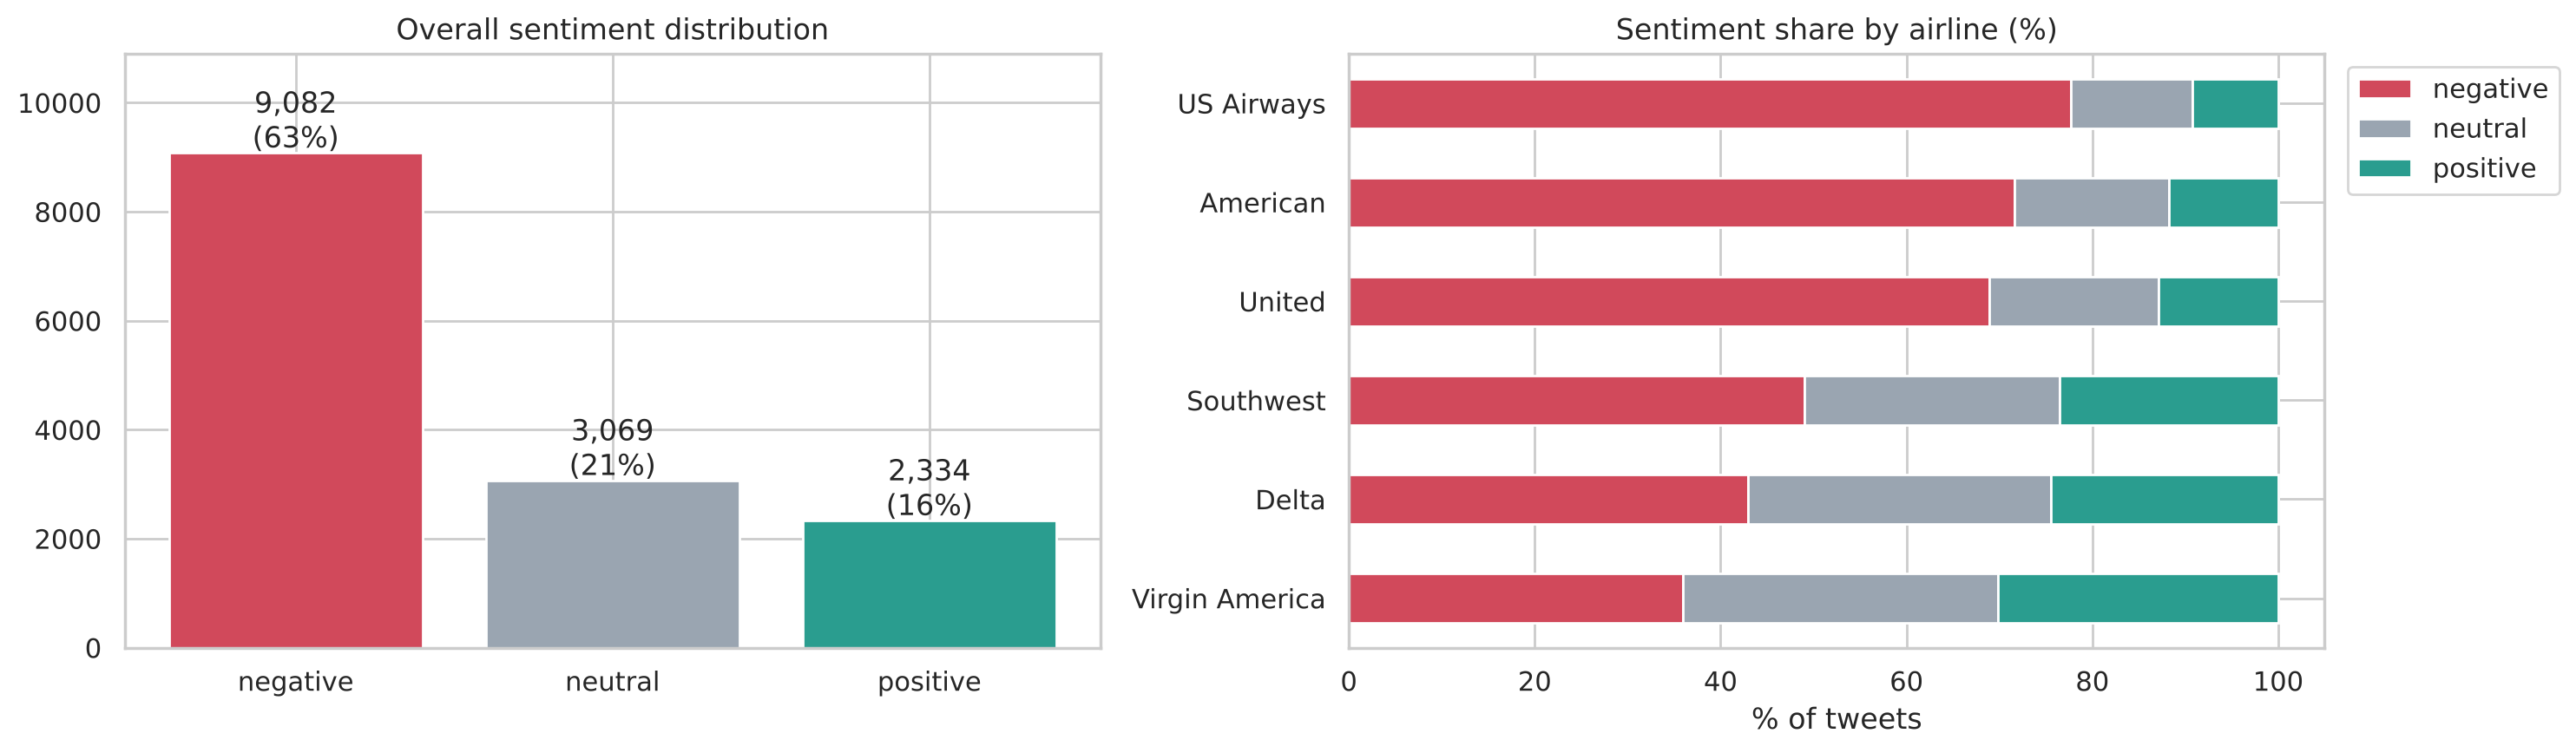

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
counts = df["airline_sentiment"].value_counts().reindex(LABELS)
axes[0].bar(counts.index, counts.values, color=[PALETTE[l] for l in LABELS])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 100, f"{v:,}\n({v / len(df):.0%})", ha="center")
axes[0].set_title("Overall sentiment distribution")
axes[0].set_ylim(0, counts.max() * 1.2)

by_airline = pd.crosstab(df["airline"], df["airline_sentiment"], normalize="index")[LABELS] * 100
by_airline = by_airline.sort_values("negative")
by_airline.plot.barh(stacked=True, ax=axes[1], color=[PALETTE[l] for l in LABELS])
axes[1].set_title("Sentiment share by airline (%)")
axes[1].set_xlabel("% of tweets")
axes[1].set_ylabel("")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

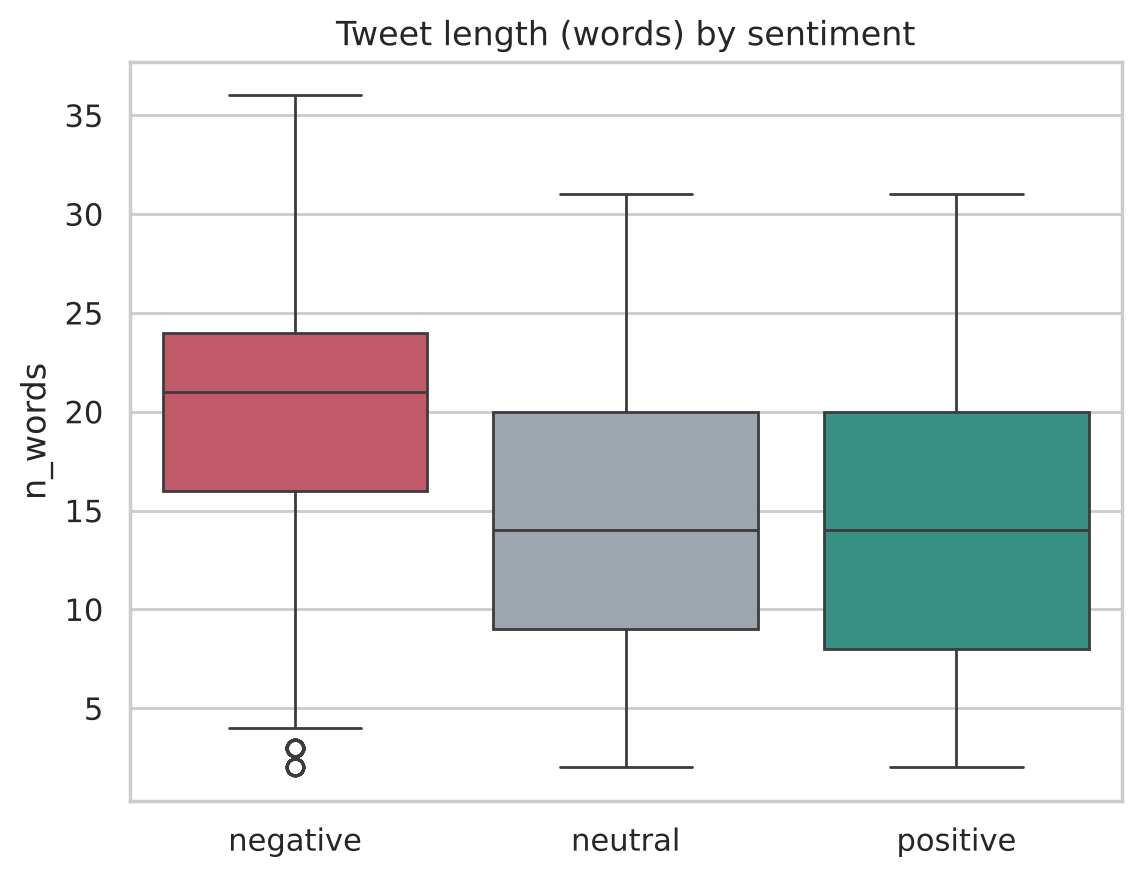

,median_words
airline_sentiment,
negative,21.0
neutral,14.0
positive,14.0


In [4]:
# Tweet length by sentiment
df["n_words"] = df["text"].str.split().str.len()
sns.boxplot(data=df, x="airline_sentiment", y="n_words", order=LABELS, palette=PALETTE)
plt.title("Tweet length (words) by sentiment")
plt.xlabel("")
plt.show()
df.groupby("airline_sentiment")["n_words"].median().to_frame("median_words")

**Observations:** most tweets are **negative** (~63%), because people mostly tweet at airlines to complain. The classes are imbalanced, so we report **macro-F1** (which treats all three classes equally) alongside accuracy. Negative tweets also tend to be longer: people explain what went wrong.

## 2. Text preprocessing
Tweets are noisy. The cleaning steps are:
1. Lower-case the text
2. Remove URLs, @mentions (the airline handle gives the answer away) and HTML entities like `&amp;`
3. Keep the words from hashtags (`#fail` → `fail`)
4. Remove numbers and punctuation
5. Tokenise, remove stop words **but keep negations** ("not", "no", "never"), because they flip sentiment
6. Lemmatise (e.g. "flights" → "flight", "delayed" → "delay")

In [5]:
lemmatizer = WordNetLemmatizer()
negations = {"no", "not", "nor", "never", "don't", "didn't", "doesn't", "isn't", "wasn't",
             "aren't", "weren't", "won't", "can't", "couldn't", "shouldn't", "wouldn't", "haven't", "hasn't"}
stop_words = set(stopwords.words("english")) - negations

def clean_text(text):
    """Clean one tweet and return a string of lemmatised tokens."""
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)          # URLs
    text = re.sub(r"@\w+", " ", text)                       # @mentions
    text = re.sub(r"&\w+;", " ", text)                      # HTML entities (&amp; etc.)
    text = text.replace("#", " ")                           # keep hashtag words
    text = re.sub(r"n't", " not", text)                     # can't -> ca not, didn't -> did not
    text = re.sub(r"[^a-z\s]", " ", text)                   # numbers, punctuation, emoji
    tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t), pos="v")
              for t in text.split() if t not in stop_words and len(t) > 1]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_text)

# Show a few before/after examples
pd.set_option("display.max_colwidth", 120)
df[["text", "clean_text"]].sample(6, random_state=1)

,text,clean_text
516,@united Thanks. It is on the same ticket.,thank ticket
3807,@united I already sent feedback and your reps are who told me about the priority. I'm speechless at your system,already send feedback rep tell priority speechless system
11049,"@USAirways @AskPayPal completed. If that's the case then why does it still say ""in progress"" on Paypal's website. I ...",complete case still say progress paypal website reserve th
7704,@JetBlue @L_Burley11 -- the best!!!,best
5453,@SouthwestAir Salted or honey roasted? I vote to bring back the salted peanuts. I dread a year of the honey roasted!...,salt honey roast vote bring back salt peanut dread year honey roast
3325,"@united Club DEN, East or West, both are disgusting. http://t.co/XijYrPsLZK",club den east west disgust


In [6]:
# Remove tweets that end up empty after cleaning
before = len(df)
df = df[df["clean_text"].str.strip() != ""]
print(f"Removed {before - len(df)} empty tweets, {len(df):,} remain")

Removed 21 empty tweets, 14,464 remain


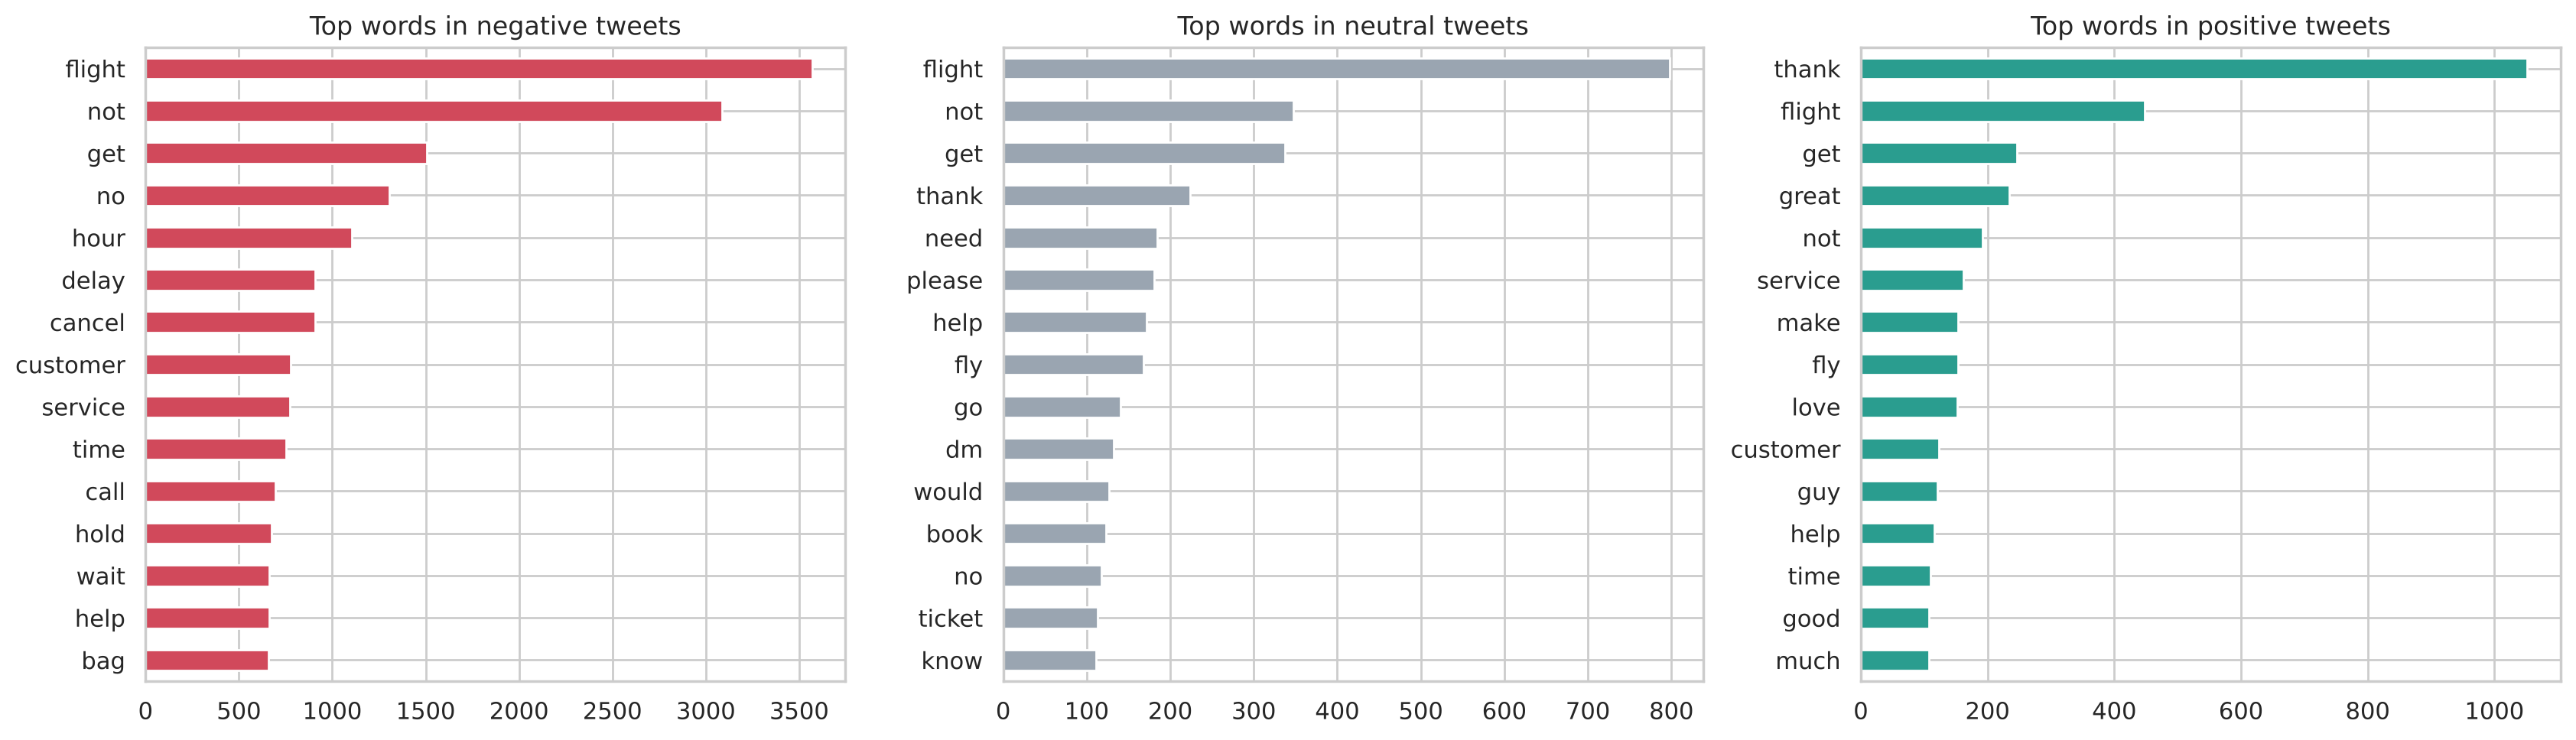

In [7]:
# Most frequent words per sentiment class (after cleaning)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, label in zip(axes, LABELS):
    cv = CountVectorizer(max_features=15)
    m = cv.fit_transform(df.loc[df["airline_sentiment"] == label, "clean_text"])
    freq = pd.Series(np.asarray(m.sum(axis=0)).ravel(), index=cv.get_feature_names_out()).sort_values()
    freq.plot.barh(ax=ax, color=PALETTE[label])
    ax.set_title(f"Top words in {label} tweets")
plt.tight_layout()
plt.show()

## 3. Model 1: VADER (rule-based baseline)
**VADER** is a sentiment lexicon built for social media. It needs **no training**: it scores each word, adjusts for negation, capitals and punctuation, and returns a *compound* score from −1 (very negative) to +1 (very positive). We map the score to a label using the standard ±0.05 thresholds.

VADER works on the **raw** text, because it uses capitals, punctuation and emoticons as signals.

In [8]:
sia = SentimentIntensityAnalyzer()

def vader_label(text, threshold=0.05):
    text = re.sub(r"@\w+", "", text)   # drop handles only
    score = sia.polarity_scores(text)["compound"]
    if score >= threshold:
        return "positive"
    if score <= -threshold:
        return "negative"
    return "neutral"

# Split once and use the same test set for every model
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["airline_sentiment"],
                                     random_state=RANDOM_STATE)
print("Train:", len(train_df), " Test:", len(test_df))

vader_pred = test_df["text"].apply(vader_label)
vader_acc = accuracy_score(test_df["airline_sentiment"], vader_pred)
vader_f1 = f1_score(test_df["airline_sentiment"], vader_pred, average="macro")
print(f"VADER  accuracy: {vader_acc:.3f}   macro-F1: {vader_f1:.3f}\n")
print(classification_report(test_df["airline_sentiment"], vader_pred))

Train: 11571  Test: 2893


VADER  accuracy: 0.544   macro-F1: 0.507

              precision    recall  f1-score   support

    negative       0.89      0.51      0.65      1815
     neutral       0.38      0.40      0.39       612
    positive       0.33      0.86      0.48       466

    accuracy                           0.54      2893
   macro avg       0.53      0.59      0.51      2893
weighted avg       0.69      0.54      0.57      2893



VADER is a quick baseline, but it has trouble with airline-specific language. For example, "my flight was **Cancelled Flightled** again" or "still waiting on hold" contain no obviously negative words. A model trained on this domain should do better.

## 4. Model 2: TF-IDF + machine-learning classifiers
**TF-IDF** turns each tweet into a vector of word weights. A word gets a high weight if it is frequent in the tweet but rare across all tweets. We use **unigrams and bigrams** (single words and word pairs such as "not happy" or "customer service"), then train three classifiers.

In [9]:
X_train, y_train = train_df["clean_text"], train_df["airline_sentiment"]
X_test, y_test = test_df["clean_text"], test_df["airline_sentiment"]

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)

candidates = {
    "Naive Bayes": Pipeline([("tfidf", tfidf()), ("clf", MultinomialNB())]),
    "Logistic Regression": Pipeline([("tfidf", tfidf()),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Linear SVM": Pipeline([("tfidf", tfidf()), ("clf", LinearSVC(class_weight="balanced"))]),
}

results = [{"model": "VADER (lexicon)", "accuracy": vader_acc, "macro_f1": vader_f1}]
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                    "macro_f1": f1_score(y_test, pred, average="macro")})
results = pd.DataFrame(results).set_index("model").round(3)
results

,accuracy,macro_f1
model,,
VADER (lexicon),0.544,0.507
Naive Bayes,0.713,0.528
Logistic Regression,0.770,0.718
Linear SVM,0.774,0.711


### Hyperparameter tuning
We tune the regularisation strength `C` of the Logistic Regression and Linear SVM, plus the TF-IDF n-gram range, with 5-fold cross-validation (scored on macro-F1).

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
tuned = {}
for name in ["Logistic Regression", "Linear SVM"]:
    grid = {"clf__C": [0.1, 0.5, 1, 2, 5], "tfidf__ngram_range": [(1, 1), (1, 2)]}
    search = GridSearchCV(candidates[name], grid, scoring="f1_macro", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"{name}: best params {search.best_params_}, CV macro-F1 {search.best_score_:.3f}")

best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_model = tuned[best_name].best_estimator_
best_pred = best_model.predict(X_test)
print(f"\nSelected model: {best_name} (tuned)")
print(f"Test accuracy: {accuracy_score(y_test, best_pred):.3f}   "
      f"macro-F1: {f1_score(y_test, best_pred, average='macro'):.3f}\n")
print(classification_report(y_test, best_pred))

Logistic Regression: best params {'clf__C': 0.5, 'tfidf__ngram_range': (1, 2)}, CV macro-F1 0.726


Linear SVM: best params {'clf__C': 0.1, 'tfidf__ngram_range': (1, 1)}, CV macro-F1 0.733

Selected model: Linear SVM (tuned)
Test accuracy: 0.778   macro-F1: 0.716

              precision    recall  f1-score   support

    negative       0.86      0.86      0.86      1815
     neutral       0.58      0.58      0.58       612
    positive       0.72      0.70      0.71       466

    accuracy                           0.78      2893
   macro avg       0.72      0.71      0.72      2893
weighted avg       0.78      0.78      0.78      2893



## 5. Evaluation and error analysis

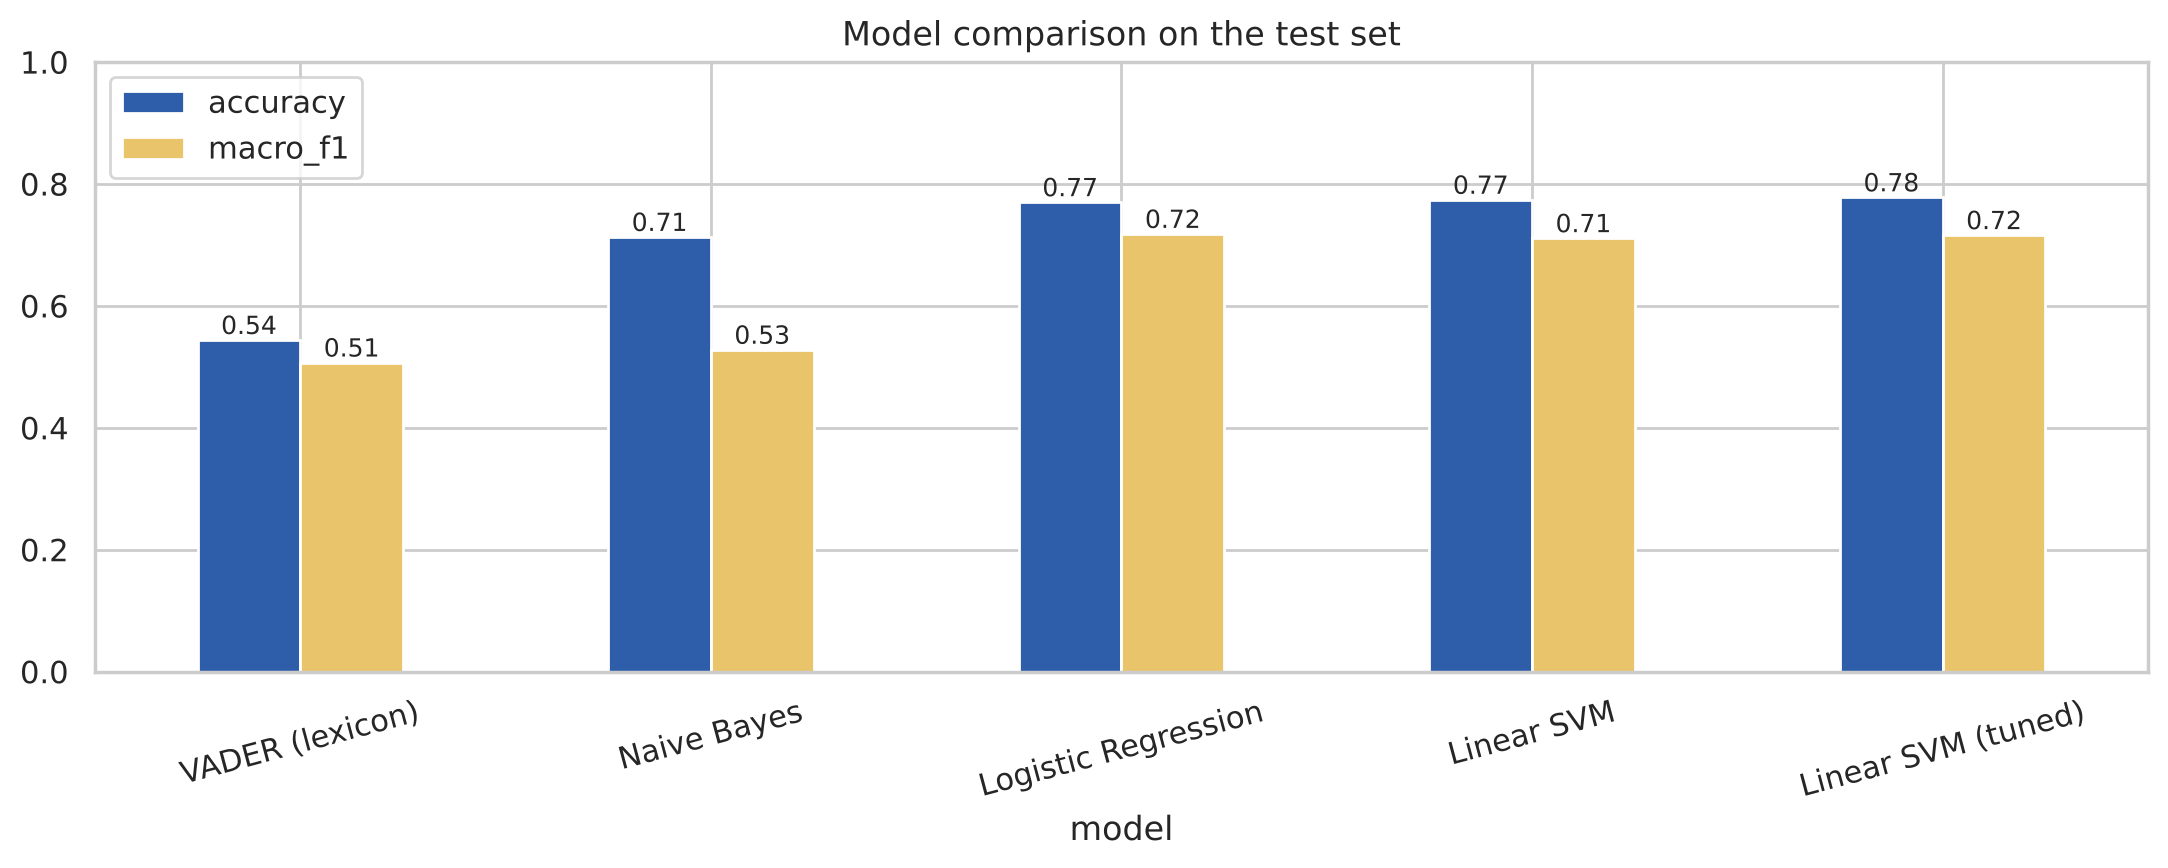

In [11]:
# Compare all models
results.loc[f"{best_name} (tuned)"] = [round(accuracy_score(y_test, best_pred), 3),
                                       round(f1_score(y_test, best_pred, average="macro"), 3)]
ax = results.plot.bar(figsize=(11, 4.5), color=["#2E5EAA", "#E9C46A"], rot=15)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=9)
ax.set_ylim(0, 1)
ax.set_title("Model comparison on the test set")
plt.tight_layout()
plt.show()

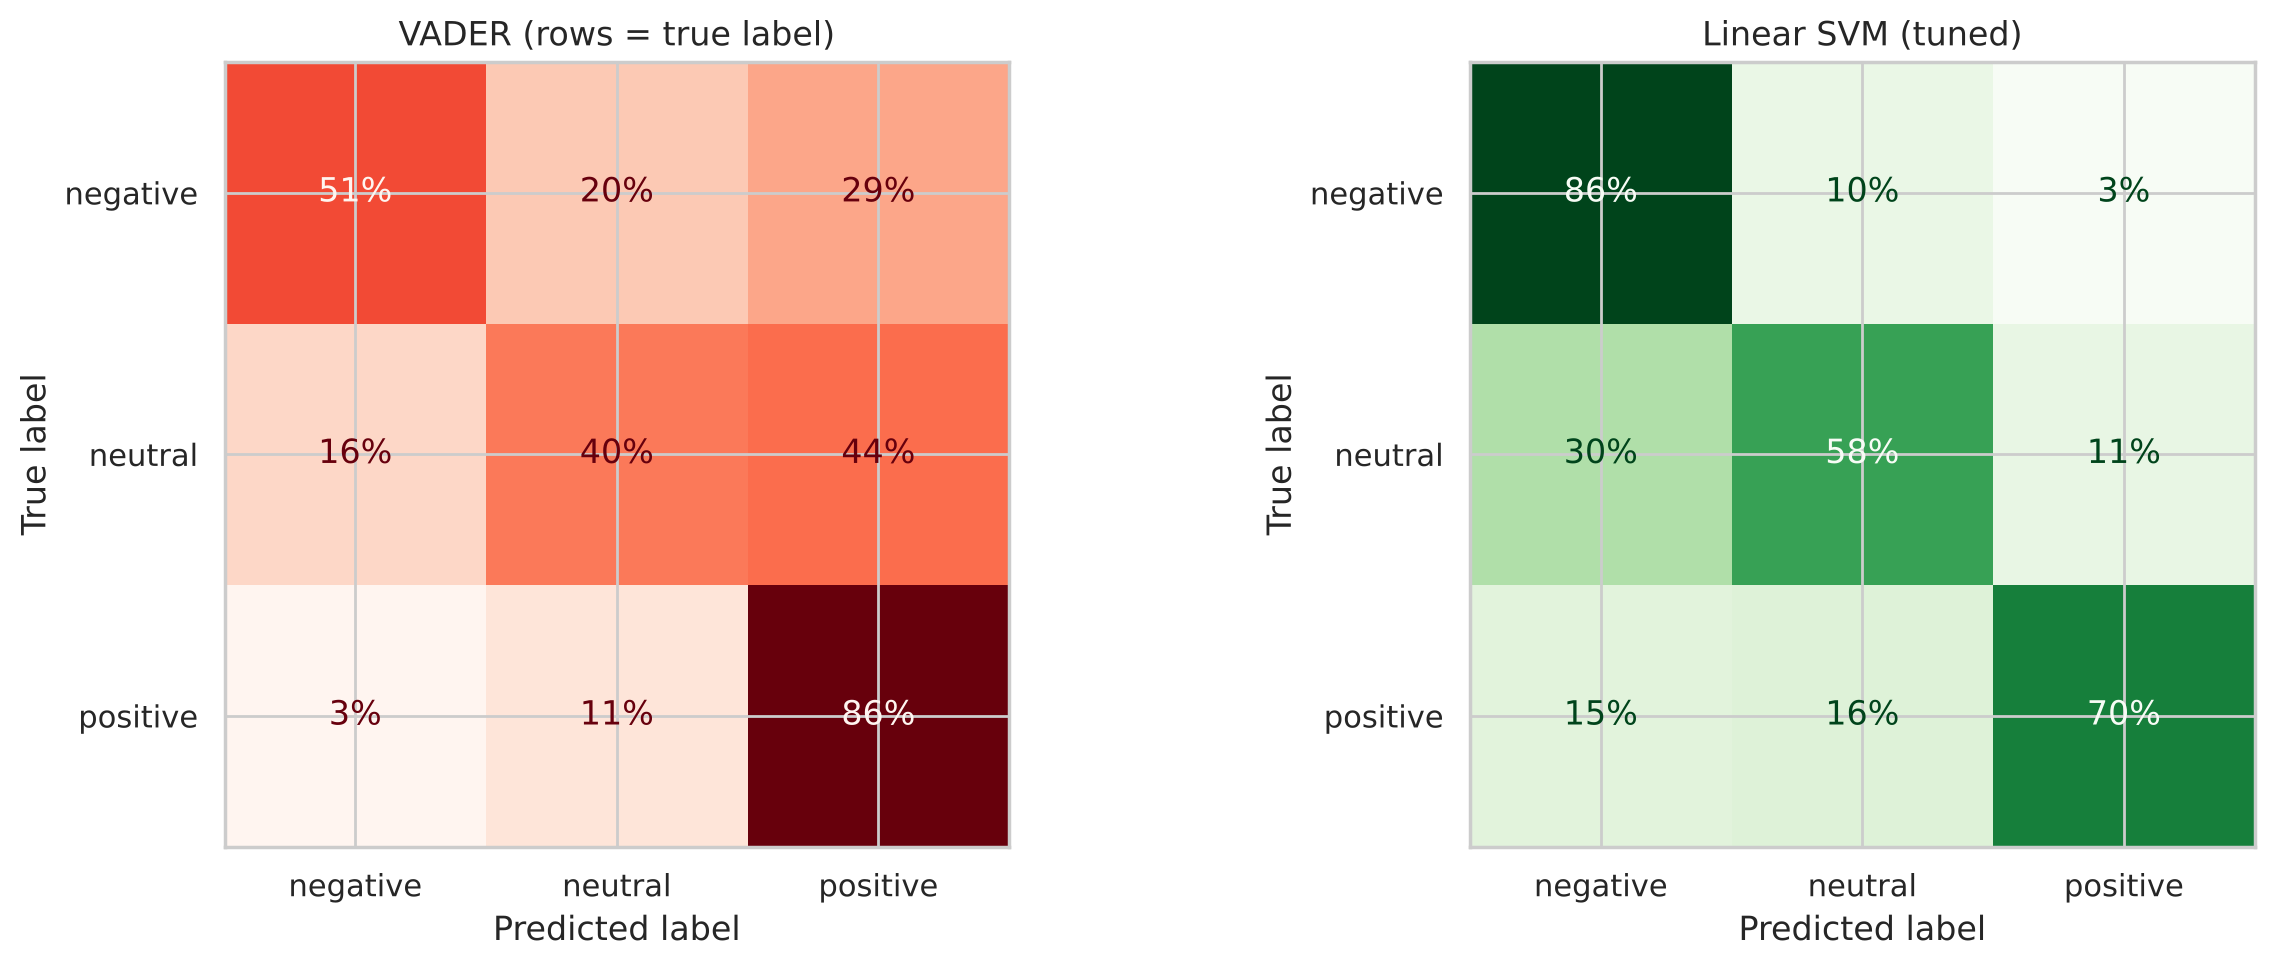

In [12]:
# Confusion matrices: VADER vs best ML model
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, vader_pred, labels=LABELS, ax=axes[0],
                                        cmap="Reds", normalize="true", values_format=".0%", colorbar=False)
axes[0].set_title("VADER (rows = true label)")
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, labels=LABELS, ax=axes[1],
                                        cmap="Greens", normalize="true", values_format=".0%", colorbar=False)
axes[1].set_title(f"{best_name} (tuned)")
plt.tight_layout()
plt.show()

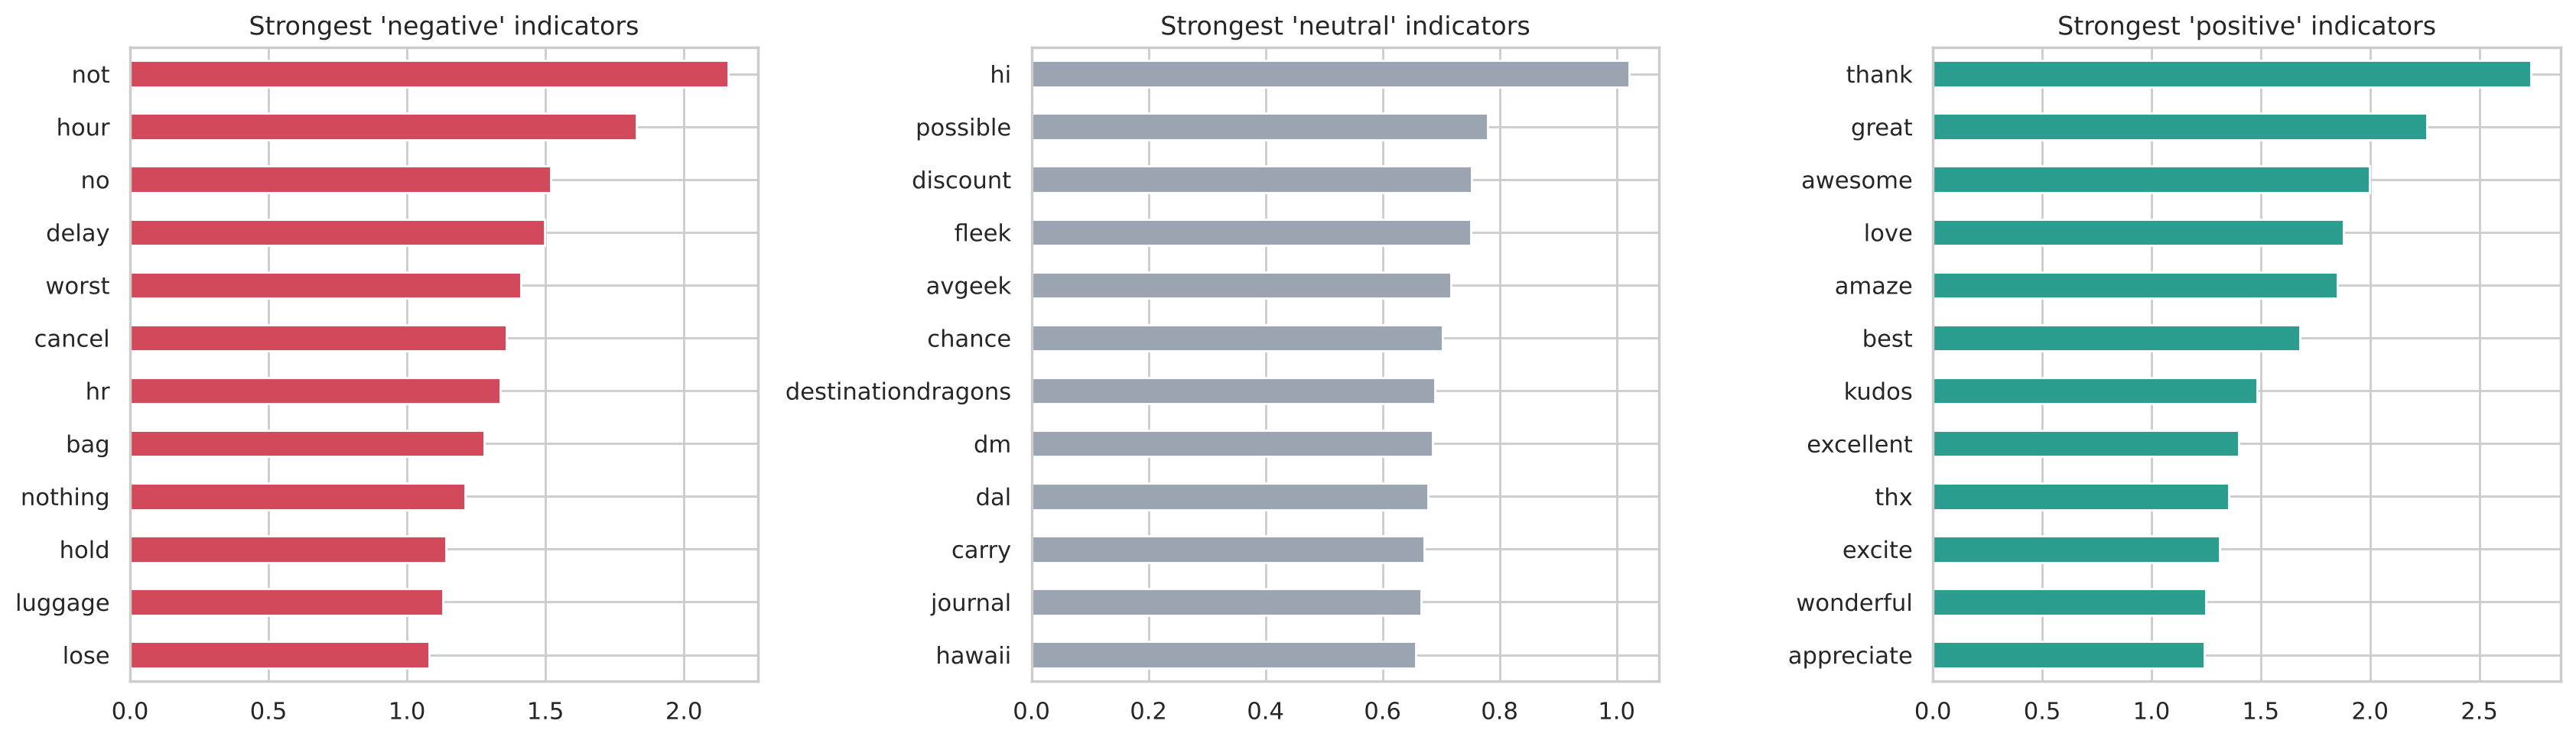

In [13]:
# Which words push the model towards each class?
vec = best_model.named_steps["tfidf"]
clf = best_model.named_steps["clf"]
features = vec.get_feature_names_out()
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (i, label) in zip(axes, enumerate(clf.classes_)):
    top = pd.Series(clf.coef_[i], index=features).nlargest(12).sort_values()
    top.plot.barh(ax=ax, color=PALETTE[label])
    ax.set_title(f"Strongest '{label}' indicators")
plt.tight_layout()
plt.show()

In [14]:
# Look at some mistakes
errors = test_df.assign(predicted=best_pred)
errors = errors[errors["predicted"] != errors["airline_sentiment"]]
print(f"{len(errors)} misclassified tweets out of {len(test_df)}")
errors[["text", "airline_sentiment", "predicted"]].head(8)

643 misclassified tweets out of 2893


,text,airline_sentiment,predicted
12362,@AmericanAir @USAirways She's on Manch to Charlotte Fl 4628 Told her she could get on a 4pm flight to West Palm Beac...,neutral,negative
2414,@united But it's doubtful he'll fly United again and he will be traveling a lot as a sales manager covering all of N...,negative,neutral
7718,@JetBlue Are we able to change to an Even More Space seat after we've checked in online? Have a flight tmrw and can'...,neutral,negative
4506,"@SouthwestAir quick question - i bought wifi for my phone, do I have to buy it again on my tablet? I have 9 hours le...",neutral,negative
5280,"@SouthwestAir flight 3899 HOU to MDW aboard a Boeing 73, boarded for an on-time 2PM departure. #WheelsUp #fb",neutral,negative
11861,@USAirways @AmericanAir you make Spirit look like the gem of air travel. You haven't handle this winter storm very w...,negative,positive
4992,@SouthwestAir my flight continues through to Vegas after my stop. Don't be upset if a stowaway.,neutral,negative
4372,@SouthwestAir round-trip tickets just arrived for our auction at the Post-Masters Invitational! Thanks Southwest! ht...,positive,neutral


**Error analysis:** most mistakes involve the **neutral** class. Many "neutral" tweets are questions ("Do you fly to X?") that share words with complaints, and sarcastic tweets ("Great, another delay 👏") look positive on the surface. These cases are hard even for human annotators. The `airline_sentiment_confidence` column shows the annotators themselves were often unsure.

In [15]:
# Try the model on new sentences
examples = [
    "Thank you so much for the upgrade, the crew was amazing!",
    "Flight delayed 3 hours and nobody tells us anything. Worst airline ever.",
    "What time does the check-in counter open tomorrow?",
    "Lost my bag again. Customer service won't even pick up the phone.",
]
pd.DataFrame({"tweet": examples,
              "predicted": best_model.predict([clean_text(t) for t in examples])})

,tweet,predicted
0,"Thank you so much for the upgrade, the crew was amazing!",positive
1,Flight delayed 3 hours and nobody tells us anything. Worst airline ever.,negative
2,What time does the check-in counter open tomorrow?,neutral
3,Lost my bag again. Customer service won't even pick up the phone.,negative


## 6. Business insights for the airlines

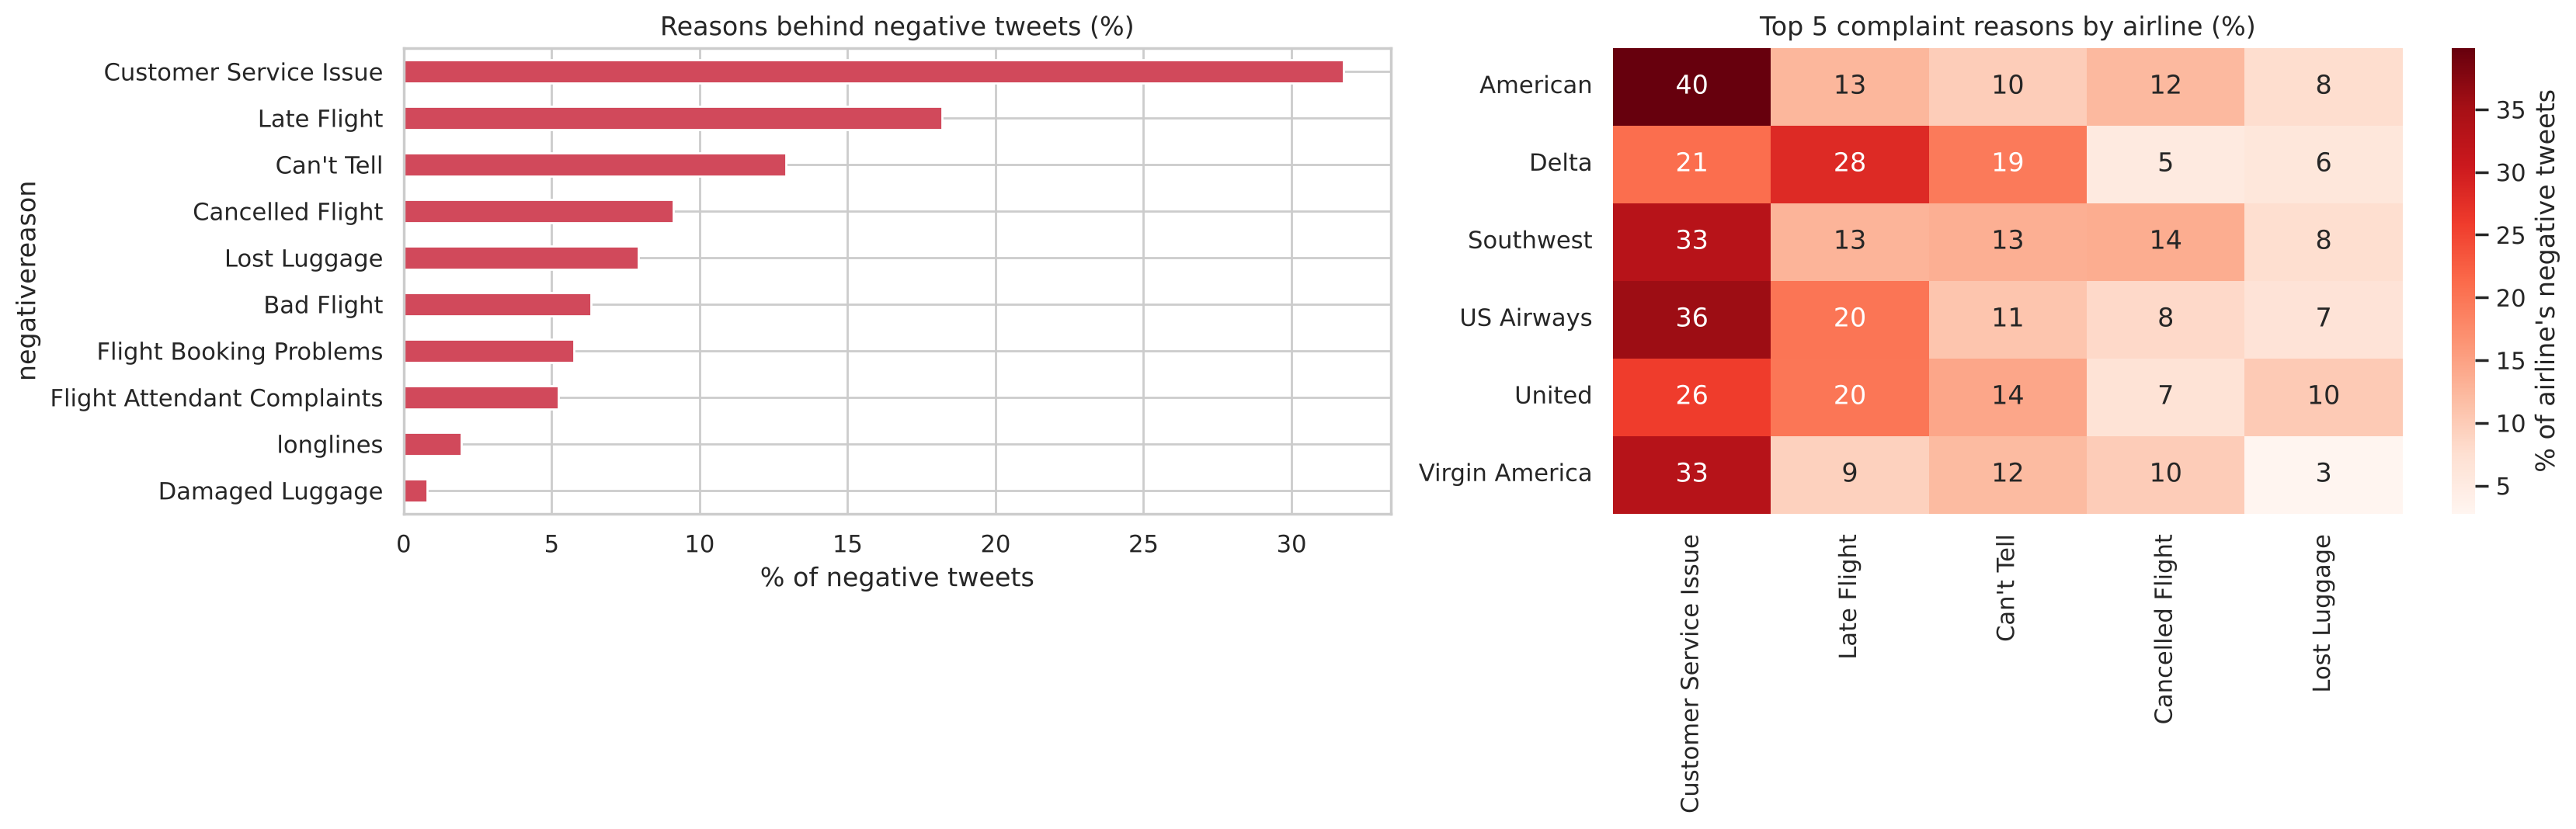

In [16]:
# Why are customers unhappy? (negative reasons given by annotators)
neg = df[df["airline_sentiment"] == "negative"]
reasons = neg["negativereason"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
(reasons / reasons.sum() * 100).sort_values().plot.barh(ax=axes[0], color="#D1495B")
axes[0].set_title("Reasons behind negative tweets (%)")
axes[0].set_xlabel("% of negative tweets")

reason_by_airline = pd.crosstab(neg["airline"], neg["negativereason"], normalize="index") * 100
top_reasons = reasons.index[:5]
sns.heatmap(reason_by_airline[top_reasons], annot=True, fmt=".0f", cmap="Reds", ax=axes[1],
            cbar_kws={"label": "% of airline's negative tweets"})
axes[1].set_title("Top 5 complaint reasons by airline (%)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

In [17]:
# Net sentiment score per airline = % positive - % negative
summary = pd.crosstab(df["airline"], df["airline_sentiment"], normalize="index")[LABELS] * 100
summary["net_sentiment"] = summary["positive"] - summary["negative"]
summary["tweets"] = df["airline"].value_counts()
summary["top_complaint"] = neg.groupby("airline")["negativereason"].agg(lambda s: s.value_counts().idxmax())
summary.sort_values("net_sentiment", ascending=False).round(1)

airline_sentiment,negative,neutral,positive,net_sentiment,tweets,top_complaint
airline,,,,,,
Virgin America,35.9,33.9,30.2,-5.8,504,Customer Service Issue
Delta,43.0,32.4,24.5,-18.5,2219,Late Flight
Southwest,49.1,27.3,23.6,-25.5,2417,Customer Service Issue
United,68.9,18.2,12.9,-56.1,3818,Customer Service Issue
American,71.7,16.5,11.8,-59.8,2600,Customer Service Issue
US Airways,77.7,13.1,9.2,-68.5,2906,Customer Service Issue


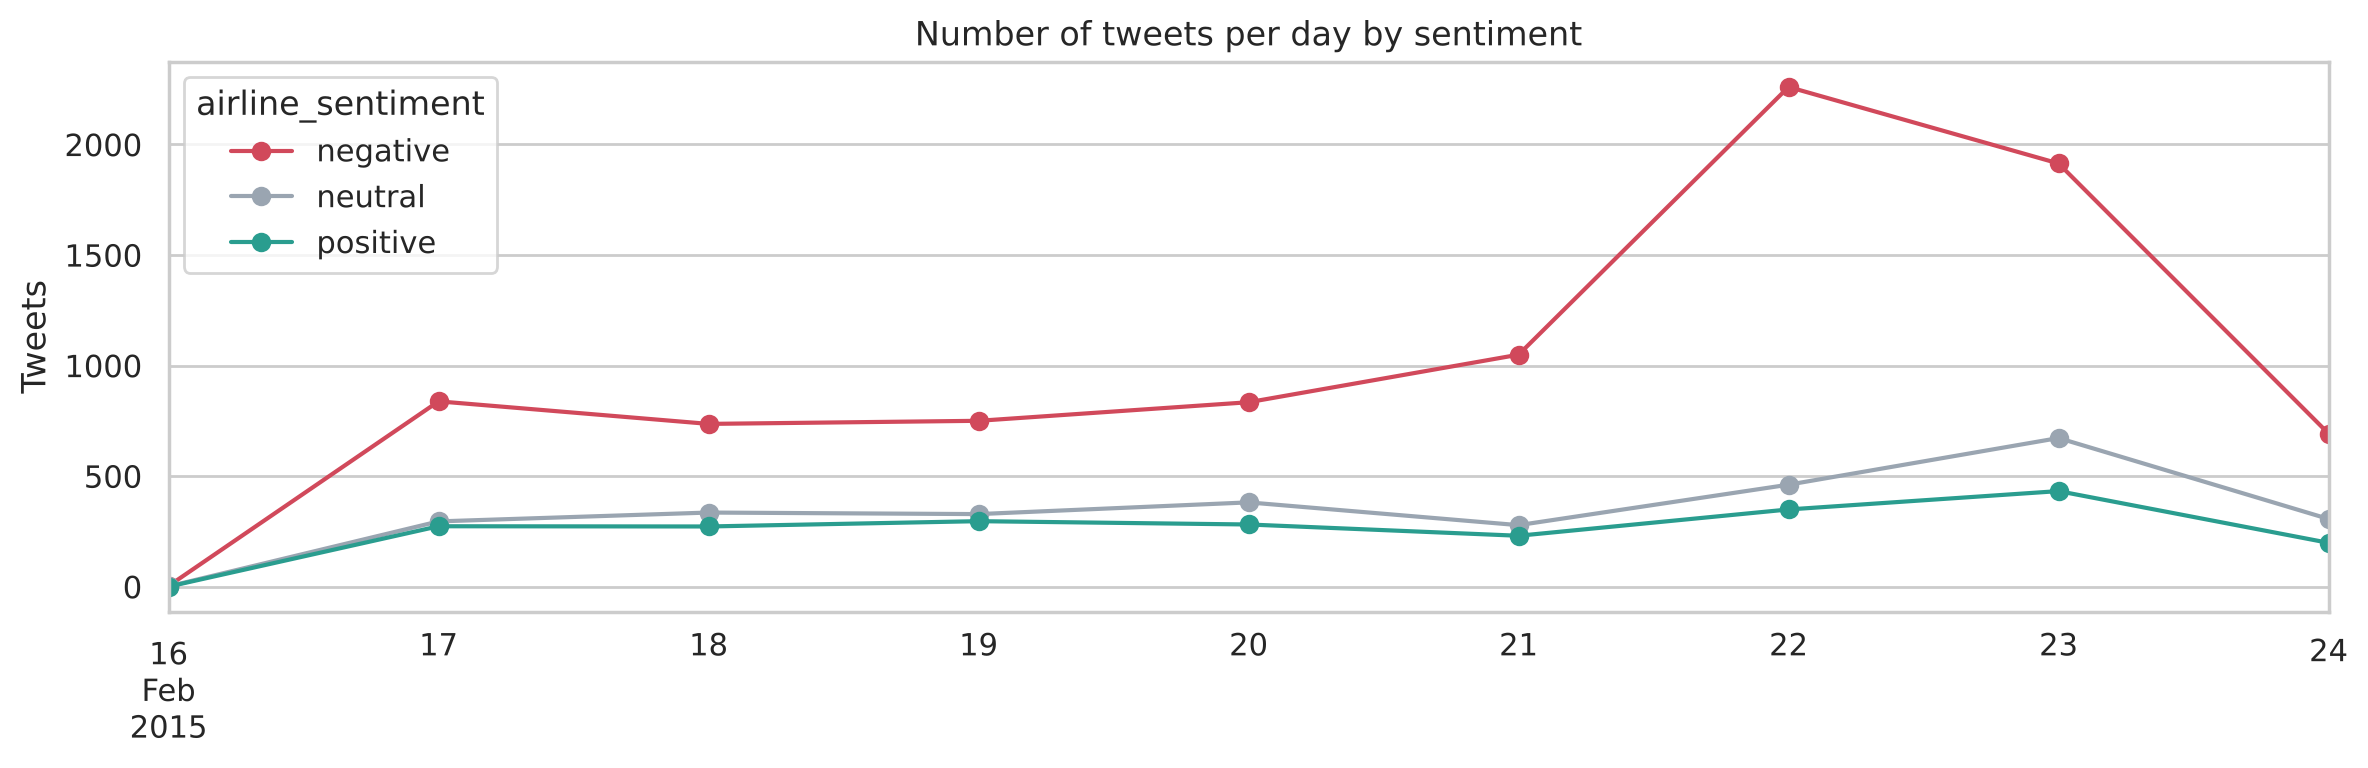

In [18]:
# Sentiment over time (by day)
df["date"] = pd.to_datetime(df["tweet_created"].str[:10])
daily = pd.crosstab(df["date"], df["airline_sentiment"])[LABELS]
daily.plot(figsize=(12, 4), color=[PALETTE[l] for l in LABELS], marker="o")
plt.title("Number of tweets per day by sentiment")
plt.ylabel("Tweets")
plt.xlabel("")
plt.tight_layout()
plt.show()

### Summary

**Preprocessing:** URL, mention and punctuation removal, negation-aware stop-word removal, and lemmatisation turned noisy tweets into clean tokens. Keeping "not"/"no" mattered, because phrases like "not happy" and "no help" are key negative signals.

**Models:**
- The rule-based **VADER** baseline needs no training but reached only about **0.54 accuracy** (macro-F1 about 0.51). It misses domain language such as "Cancelled Flightled", "on hold" and "delayed".
- **TF-IDF + Logistic Regression / Linear SVM** trained on the airline tweets did much better, at **about 0.77–0.78 accuracy** and **macro-F1 about 0.72**. The tuned model therefore gets roughly 4 out of 5 tweets right. Naive Bayes reached good accuracy but mostly ignored the smaller classes (low macro-F1).
- **Negative** tweets are recognised very reliably (F1 about 0.86). **Neutral** is the hardest class (questions, sarcasm, mixed tweets).

**Insights for the airlines:**
- **About 63% of tweets are negative** (only 16% are positive). Twitter is mainly a complaints channel, so fast and helpful replies there matter.
- **Customer service issues** (about 32% of complaints) and **late flights** (about 18%) are the two biggest reasons, followed by cancellations and lost luggage. The model's strongest negative words (see the chart) point to the same problems.
- **US Airways, American and United** have the most negative sentiment. **Virgin America** has the best net sentiment, followed by Delta and Southwest.
- Each airline has its own pain point (see the heatmap). For example, **customer service** dominates US Airways and American complaints, while **late flights** are relatively bigger for Delta. Each airline should focus on its own top issue.
- **Recommendation:** use the trained model to **sort incoming tweets automatically** and send negative ones (especially about cancellations and lost bags) to the support team first.

*Exact figures for each point are in the outputs above.*